# M5. SVD·저차원 근사·NMF: 큰 행렬을 몇 개의 조각으로

**목표**
- 모든 행렬은 **회전 → 늘이기 → 회전**으로 쪼개진다는 SVD 를 그림으로 봅니다.
- SVD 를 "rank-1 조각들의 합"(M2 의 네 번째 눈)으로 읽고, 큰 조각 몇 개만 남기는 저차원 근사가 왜 가장 좋은지 봅니다.
- SVD 와 PCA(M4)가 같은 것이라는 것을 확인합니다.
- 음수 없이 쪼개는 NMF 를 직접 짜고, mutational signature 추출(catalogue = signature × 노출량)에 씁니다.
- LLM 의 LoRA 가 "낮은 rank 의 갱신"이라는 것을 봅니다.

**이 노트북이 답하는 질문**: 큰 표(예: 96 × 표본 수 catalogue)를 몇 개의 "재료"와 "양"으로 쪼갤 수 있나? 쪼개는 방법은 왜 여러 가지인가?

**같이 볼 강의**
- MIT 18.06 (Strang, 2010 봄) Lecture 29 "Singular value decomposition", Lecture 31 "Change of basis; image compression", Lecture 33 "Left and right inverses; pseudoinverse" [1]
- (3Blue1Brown "Essence of linear algebra" 16 개 장에는 SVD 를 다루는 장이 없습니다 [2])

문장 끝의 `[번호]` 는 맨 아래 **출처** 절의 번호입니다. 그림 속 숫자와 signature 는 따로 밝히지 않으면 **이 노트북의 장난감 예**입니다. 공분산과 PCA 는 [M4](lab04_eigen-pca.ipynb), rank-1 조각은 [M2](lab02_matrix-multiplication.ipynb), NNLS 는 [M3](lab03_least-squares.ipynb)를 보세요.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 색의 뜻은 행렬 노트북 M1~M5 공통
# e1·첫째 열 = 파랑, e2·둘째 열 = 빨강, 결과 = 초록, 변환 전 격자 = 옅은 회색, 변환 뒤 격자 = 진회색, 핵심 메시지 = 자주
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Polygon, Rectangle

COL = dict(e1="#0072B2", e2="#D55E00", result="#009E73", grid0="#D1D5DB", grid1="#374151",
           extra="#E69F00", sky="#56B4E9", highlight="#CC79A7", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", shade="#FFF4E0", neutral="#F3F4F6")


def apply_theme():
    import logging
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """핵심 메시지: 자주색 굵은 글씨(흰 바탕)"""
    kw.setdefault("fontsize", 10); kw.setdefault("ha", "left"); kw.setdefault("va", "center")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, color=COL["highlight"], fontweight="semibold", **kw)


def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.014):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다.
    조각마다 '조각과 이름표 중 넓은 쪽' 만큼 자리를 잡아 이름표끼리 겹치지 않게 한다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lab, lw = None, 0.0
        if label:
            lab = ax.text(0, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                          color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)
            lw = lab.get_window_extent(renderer=r).transformed(inv).width
        items.append((t, bb, color, lab, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, lab, w in items:
        x0 = x + (w - bb.width) / 2                         # 자리 가운데에 조각
        t.set_x(x0)
        if color:
            ax.add_patch(FancyBboxPatch((x0 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if lab is not None:
            lab.set_x(x0 + bb.width / 2)
        x += w + gap


def show_formula(parts, title=None, height=1.35, width=10.5, fontsize=17):
    """수식 조각 그림 한 장(제목은 가운데)"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts, fontsize=fontsize)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11, fontweight="semibold",
                color=COL["ink"], transform=ax.transAxes)
    plt.show()


def arrow(ax, start, end, color, lw=2.2, label=None, label_off=(0.08, 0.08), zorder=4, ls="-", **kw):
    """두 점 사이 화살표(데이터 좌표) + 끝에 이름표"""
    a = FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, lw=lw, color=color,
                        zorder=zorder, linestyle=ls, shrinkA=0, shrinkB=0)
    ax.add_patch(a)
    if label:
        ax.text(end[0] + label_off[0], end[1] + label_off[1], label, color=color, fontsize=10.5,
                fontweight="semibold", zorder=zorder + 1, **kw)
    return a


def concept_map(boxes, edges, title="Concept map", size=(11, 3.6)):
    """개념 지도: boxes = {key: (x, y, text, color)}, edges = [(from, to), ...] (축 좌표 0~1)"""
    fig, ax = plt.subplots(figsize=size); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    for k, (x, y, text, color) in boxes.items():
        ax.text(x, y, text, ha="center", va="center", fontsize=9.5, color=COL["ink"], zorder=3,
                bbox=dict(boxstyle="round,pad=0.45", facecolor=color, edgecolor="none", alpha=0.9))
    for a, b in edges:
        (x0, y0, *_), (x1, y1, *_) = boxes[a], boxes[b]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.1,
                                    shrinkA=26, shrinkB=26, connectionstyle="arc3,rad=0.0"))
    ax.set_title(title)
    plt.show()


apply_theme()
CLASSES = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
CLASS_COL = ["#56B4E9", "#000000", "#D55E00", "#BBBBBB", "#009E73", "#CC79A7"]   # 96칸 그림의 관례적 6색


def draw_concept_map_m5():
    boxes = {
        "any": (0.08, 0.55, "any matrix A", COL["neutral"]),
        "svd": (0.26, 0.85, "SVD:\nrotate·stretch·rotate", "#DCEBF7"),
        "r1": (0.26, 0.25, "sum of rank-1\npieces σ u vᵀ", "#DCEBF7"),
        "lr": (0.47, 0.25, "keep the k biggest\n= best rank-k", "#D9F2E6"),
        "pca": (0.47, 0.85, "SVD of centred data\n= PCA", COL["neutral"]),
        "nn": (0.67, 0.55, "non-negative world:\ncounts, recipes", COL["neutral"]),
        "nmf": (0.86, 0.85, "NMF: V ≈ W H,\nW, H ≥ 0", "#D9F2E6"),
        "sig": (0.86, 0.50, "signatures ×\nexposures", "#FDE7D2"),
        "lora": (0.86, 0.18, "LoRA: ΔW = B A\n(low rank)", "#FDE7D2"),
    }
    edges = [("any", "svd"), ("any", "r1"), ("svd", "pca"), ("r1", "lr"), ("lr", "nn"), ("pca", "nn"),
             ("nn", "nmf"), ("nmf", "sig"), ("lr", "lora")]
    concept_map(boxes, edges, title="M5 concept map: splitting a big matrix into a few pieces")


def draw_svd_circle(A=((2.0, 1.5), (0.3, 1.0))):
    A = np.array(A); U, s, Vt = np.linalg.svd(A)
    if np.linalg.det(U) < 0:
        U[:, 1] *= -1; Vt[1] *= -1
    t = np.linspace(0, 2 * np.pi, 300); circle = np.vstack([np.cos(t), np.sin(t)])
    stages = [("A", "Start: unit circle, v1 and v2", np.eye(2), Vt.T),
              ("B", "1. rotate by Vᵀ: v's onto the axes", Vt, np.eye(2)),
              ("C", "2. stretch by Σ", np.diag(s) @ Vt, np.diag(s)),
              ("D", "3. rotate by U  (= A)", A, U @ np.diag(s))]
    fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.7))
    for a, (let, title, M, D) in zip(ax, stages):
        P = M @ circle
        a.fill(P[0], P[1], color=COL["result"], alpha=0.1, lw=0); a.plot(P[0], P[1], color=COL["result"], lw=1.6)
        arrow(a, (0, 0), D[:, 0], COL["result"], lw=2.6); arrow(a, (0, 0), D[:, 1], COL["extra"], lw=2.6)
        a.set_xlim(-3.0, 3.0); a.set_ylim(-3.0, 3.0); a.set_aspect("equal"); a.set_axis_off()
        a.axhline(0, color=COL["grid"], lw=0.8, zorder=0); a.axvline(0, color=COL["grid"], lw=0.8, zorder=0)
        panel(a, let, title)
    callout(ax[3], -2.9, -2.8, f"σ₁ = {s[0]:.2f} (green), σ₂ = {s[1]:.2f} (orange)", fontsize=9.5, va="bottom")
    plt.tight_layout(); plt.show()
    return U, s, Vt


def toy_image(h=60, w=90):
    y, x = np.mgrid[0:h, 0:w]
    img = 0.6 * np.exp(-((x - 30) ** 2 + (y - 30) ** 2) / 180) + 0.9 * ((np.abs(x - 62) < 12) & (np.abs(y - 26) < 18))
    img += 0.35 * np.sin(x / 6.0) * (y > 44) + 0.25 * ((x + y) % 18 < 3)
    return img


def draw_rank1_pieces(img):
    U, s, Vt = np.linalg.svd(img, full_matrices=False)
    fig, ax = plt.subplots(2, 4, figsize=(12.5, 4.6), gridspec_kw={"hspace": 0.35, "wspace": 0.08})
    vmax = np.abs(img).max()
    for k in range(4):
        piece = s[k] * np.outer(U[:, k], Vt[k]); acc = (U[:, :k + 1] * s[:k + 1]) @ Vt[:k + 1]
        ax[0, k].imshow(piece, cmap="BrBG", vmin=-vmax, vmax=vmax, aspect="auto"); ax[0, k].set_axis_off()
        ax[0, k].set_title(f"{'A   ' if k == 0 else ''}piece {k + 1}: σ{k + 1} = {s[k]:.1f}", fontsize=10.5)
        ax[1, k].imshow(acc, cmap="Greys", vmin=0, vmax=vmax, aspect="auto"); ax[1, k].set_axis_off()
        ax[1, k].set_title(f"{'B   ' if k == 0 else ''}sum of the first {k + 1}", fontsize=10.5)
    plt.show()
    return U, s, Vt


def draw_low_rank(img, ks=(1, 3, 8, 20), seed=0):
    U, s, Vt = np.linalg.svd(img, full_matrices=False); rng = np.random.default_rng(seed)
    fig = plt.figure(figsize=(12.5, 6.0)); gs = fig.add_gridspec(2, 5, height_ratios=[1, 1.35], hspace=0.45, wspace=0.08)
    a0 = fig.add_subplot(gs[0, 0]); a0.imshow(img, cmap="Greys", vmin=0, vmax=img.max(), aspect="auto"); a0.set_axis_off()
    a0.set_title("A   original: 5400 numbers", fontsize=10.5)
    for i, k in enumerate(ks):
        a = fig.add_subplot(gs[0, i + 1]); Ak = (U[:, :k] * s[:k]) @ Vt[:k]
        a.imshow(Ak, cmap="Greys", vmin=0, vmax=img.max(), aspect="auto"); a.set_axis_off()
        a.set_title(f"rank {k}: {k * (img.shape[0] + img.shape[1] + 1)} numbers", fontsize=10.5)
    c = fig.add_subplot(gs[1, 1:4]); kk = np.arange(1, 31)
    err_svd = [np.sqrt(np.sum(s[k:] ** 2)) for k in kk]
    err_rand = []
    for k in kk:
        Q, _ = np.linalg.qr(rng.normal(size=(img.shape[1], k)))      # 무작위 k 차원 방향으로 투영
        err_rand.append(np.linalg.norm(img - img @ Q @ Q.T))
    rel = np.linalg.norm(img)
    c.plot(kk, np.array(err_svd) / rel, color=COL["result"], lw=2.2, marker="o", ms=3)
    c.plot(kk, np.array(err_rand) / rel, color=COL["grid1"], lw=1.6, ls="--")
    c.text(21, err_rand[20] / rel + 0.06, "random rank-k", color=COL["grid1"], fontsize=9.5)
    c.text(9, err_svd[8] / rel + 0.06, "SVD (keep the biggest σ)", color=COL["result"], fontsize=9.5, fontweight="semibold")
    c.set_xlabel("rank k"); c.set_ylabel("relative error"); c.set_ylim(0, 1.05)
    c.yaxis.grid(True); c.set_axisbelow(True)
    panel(c, "B", r"Relative error $\|A - A_k\|_F \,/\, \|A\|_F$: SVD is always lowest")
    plt.show()
    return s, err_svd, err_rand


def toy_signatures(seed=11):
    """96칸 장난감 signature 3개(COSMIC 아님). 각 열의 합 = 1"""
    rng = np.random.default_rng(seed)
    weights = [[0.1, 0.05, 0.7, 0.05, 0.05, 0.05],     # S1: C>T 위주
               [0.05, 0.05, 0.1, 0.1, 0.4, 0.3],        # S2: T>C·T>G 위주
               [0.6, 0.15, 0.1, 0.05, 0.05, 0.05]]      # S3: C>A 위주
    sigs = []
    for w in weights:
        sig = np.concatenate([w[c] * rng.dirichlet(np.full(16, 1.5)) for c in range(6)])
        sigs.append(sig / sig.sum())
    return np.column_stack(sigs)


def make_catalogues(P, G=40, seed=2):
    rng = np.random.default_rng(seed)
    E = rng.gamma(0.9, 250, (P.shape[1], G)) * (rng.random((P.shape[1], G)) < 0.75)   # 일부 표본은 어떤 signature 가 없음
    return rng.poisson(P @ E).astype(float), E


def _bars96(ax, v, ylabel=None):
    ax.bar(np.arange(96), v, color=np.repeat(CLASS_COL, 16), width=0.85)
    ax.set_xlim(-1, 96); ax.set_xticks([c * 16 + 7.5 for c in range(6)], CLASSES); ax.tick_params(axis="x", length=0)
    ax.axhline(0, color=COL["muted"], lw=0.6)
    if ylabel:
        ax.set_ylabel(ylabel)


def nmf(V, k, iters=1500, seed=0, eps=1e-12):
    """Lee & Seung 의 곱셈 갱신(유클리드 거리). 반환: W, H, 오차 기록"""
    rng = np.random.default_rng(seed)
    W = rng.random((V.shape[0], k)) + 0.1; H = rng.random((k, V.shape[1])) + 0.1
    hist = []
    for _ in range(iters):
        H *= (W.T @ V) / (W.T @ W @ H + eps)
        W *= (V @ H.T) / (W @ H @ H.T + eps)
        hist.append(np.linalg.norm(V - W @ H))
    sc = W.sum(0); W /= sc; H *= sc[:, None]            # signature 열 합 = 1 로 맞추고 노출량에 옮김
    return W, H, np.array(hist)


def match_cos(Wa, Wb):
    """두 signature 집합을 코사인 유사도로 짝짓기(작은 k 라 모든 순열을 본다)"""
    from itertools import permutations
    na = Wa / np.linalg.norm(Wa, axis=0); nb = Wb / np.linalg.norm(Wb, axis=0); Cm = na.T @ nb
    best = max(permutations(range(Wb.shape[1]), Wa.shape[1]), key=lambda p: sum(Cm[i, j] for i, j in enumerate(p)))
    return [Cm[i, j] for i, j in enumerate(best)], best


def draw_svd_vs_nmf(V, P):
    U, s, Vt = np.linalg.svd(V, full_matrices=False)
    W, H, hist = nmf(V, 3, seed=1)
    cs, perm = match_cos(P, W)
    fig, ax = plt.subplots(3, 2, figsize=(12.5, 6.6), sharex=True)
    for k in range(3):
        _bars96(ax[k, 0], U[:, k] * np.sign(U[np.argmax(np.abs(U[:, k])), k]), ylabel=f"component {k + 1}")
        _bars96(ax[k, 1], W[:, perm[k]], ylabel=f"NMF {k + 1}")
        w_ = W[:, perm[k]]; left_low = w_[:40].max() < w_[56:].max()          # 막대가 낮은 쪽에 글씨
        ax[k, 1].text(2 if left_low else 95, ax[k, 1].get_ylim()[1] * 0.85, f"cosine with toy S{k + 1} = {cs[k]:.3f}",
                      ha="left" if left_low else "right", fontsize=9.5, color=COL["result"], fontweight="semibold",
                      bbox=dict(facecolor="white", edgecolor="none", pad=1))
        if k == 0:
            panel(ax[k, 0], "A", "SVD components (left singular vectors)")
            panel(ax[k, 1], "B", "NMF columns of W (non-negative)")
    neg = (U[:, 1] < 0).mean()
    callout(ax[1, 0], 50, ax[1, 0].get_ylim()[0] * 0.6, f"{neg:.0%} of channels negative: not a recipe", fontsize=9.5)
    plt.tight_layout(); plt.show()
    return W, H, hist, cs


def draw_convergence(V, seeds=(0, 1, 2, 3)):
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    finals = []
    for sd in seeds:
        _, _, h = nmf(V, 3, iters=600, seed=sd)
        ax.plot(np.arange(1, len(h) + 1), h, lw=1.4, color=COL["grid1"], alpha=0.8)
        finals.append(h[-1])
    ax.set_xscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("‖V − W H‖ (Frobenius)")
    ax.yaxis.grid(True); ax.set_axisbelow(True)
    callout(ax, 25, (max(finals) + ax.get_ylim()[1]) / 2,
            f"never goes up (Theorem 1 of Lee & Seung)\nfinal error here: {min(finals):.1f} to {max(finals):.1f}", fontsize=9.8)
    panel(ax, "", "Multiplicative updates: error by iteration, 4 random starts")
    plt.show()
    return finals


def draw_choose_k(V, ks=range(1, 7), seeds=range(5)):
    errs, stab = [], []
    for k in ks:
        runs = [nmf(V, k, iters=800, seed=sd) for sd in seeds]
        errs.append(np.mean([np.linalg.norm(V - W @ H) for W, H, _ in runs]) / np.linalg.norm(V))
        ref = runs[0][0]
        stab.append(np.mean([np.mean(match_cos(ref, W)[0]) for W, _, _ in runs[1:]]))
    ks = list(ks)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
    ax[0].plot(ks, errs, color=COL["ink"], marker="o", lw=1.8); ax[0].set_xlabel("number of signatures k")
    ax[0].set_ylabel("relative reconstruction error"); ax[0].yaxis.grid(True); ax[0].set_axisbelow(True)
    panel(ax[0], "A", "Error keeps falling as k grows")
    ax[1].plot(ks, stab, color=COL["result"], marker="o", lw=1.8); ax[1].set_xlabel("number of signatures k")
    ax[1].set_ylabel("mean cosine between runs"); ax[1].set_ylim(min(stab) - 0.05, 1.01)
    ax[1].yaxis.grid(True); ax[1].set_axisbelow(True)
    for a in ax:
        a.axvspan(2.6, 3.4, color=COL["shade"], zorder=0, lw=0)
    callout(ax[1], 4.1, 1.0 - (1.0 - min(stab)) * 0.25, "k = 3: error has flattened,\nsignatures still agree between runs", fontsize=9.5)
    panel(ax[1], "B", "Do 5 random starts find the same signatures?")
    plt.tight_layout(); plt.show()
    return errs, stab


def draw_lora(d=4096, k=4096, r=8):
    fig, ax = plt.subplots(figsize=(11.5, 3.6)); ax.set_axis_off(); ax.set_xlim(0, 13); ax.set_ylim(-0.6, 4.4)
    def box(x, y, wdt, hgt, c, label, sub):
        ax.add_patch(FancyBboxPatch((x, y), wdt, hgt, boxstyle="round,pad=0,rounding_size=0.06", facecolor=c, alpha=0.2,
                                    edgecolor=c, lw=1.4))
        ax.text(x + wdt / 2, y + hgt / 2, label, ha="center", va="center", fontsize=13, fontweight="semibold", color=COL["ink"])
        ax.text(x + wdt / 2, y - 0.15, sub, ha="center", va="top", fontsize=9.5, color=COL["muted"])
    box(0.4, 0.4, 3.4, 3.4, COL["grid1"], "ΔW", f"{d} × {k}\n= {d * k / 1e6:.1f} M numbers")
    ax.text(4.3, 2.1, "=", fontsize=22, va="center")
    box(5.0, 0.4, 0.45, 3.4, COL["e1"], "B", f"{d} × {r}")
    ax.text(5.85, 2.1, "×", fontsize=18, va="center")
    box(6.3, 3.3, 3.4, 0.45, COL["e2"], "A", f"{r} × {k}")
    ax.text(10.0, 3.6, f"B and A together:\nr (d + k) = {r * (d + k):,} numbers", fontsize=10.5, va="top", color=COL["ink"])
    callout(ax, 10.0, 2.0, f"{d * k / (r * (d + k)):.0f}× fewer numbers to train", fontsize=11)
    ax.text(10.0, 1.2, f"rank of B A ≤ r = {r}:\na sum of {r} rank-1 pieces (M2)", fontsize=9.5, va="top", color=COL["muted"])
    plt.show()

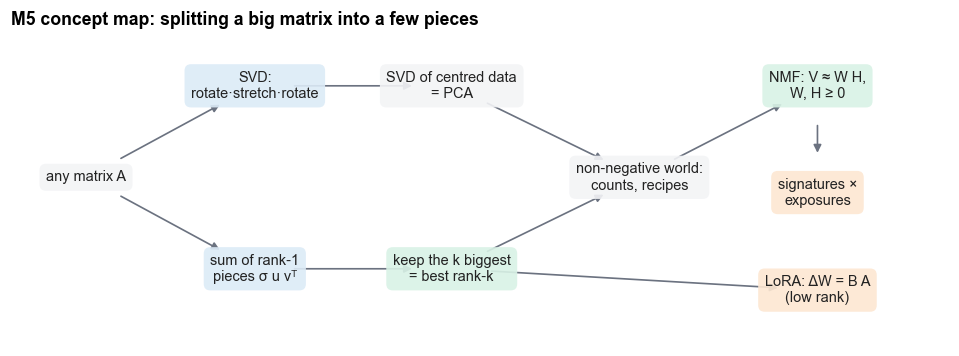

In [2]:
draw_concept_map_m5()

**그림에서 볼 것**
- 위쪽 길: 어떤 행렬이든 SVD 로 회전·늘이기·회전으로 쪼개지고, 평균을 뺀 데이터의 SVD 는 PCA(M4)와 같습니다.
- 아래쪽 길: SVD 를 rank-1 조각의 합으로 보면 "큰 조각만 남기기"(저차원 근사)가 나오고, 음수가 없는 데이터에서는 NMF 로 이어집니다.
- 오른쪽: NMF 로 signature 를 뽑는 일과 LLM 의 LoRA 가 응용입니다.

## 1. SVD: 모든 행렬은 회전 → 늘이기 → 회전

**한 줄 정의**: 어떤 행렬 A 든 $A = U\Sigma V^\top$ 로 쪼개집니다. $V^\top$ 와 U 는 회전(또는 뒤집기), Σ 는 축마다 늘이기이고, 그 배율 σ₁ ≥ σ₂ ≥ … ≥ 0 을 특잇값이라 부릅니다(아래에서 숫자로 확인).

**왜 필요한가**: M4 의 $Q\Lambda Q^\top$ 는 대칭행렬에만 됐습니다. SVD 는 대칭이 아니어도, 정사각이 아니어도 늘 됩니다. 그래서 데이터 표(표본 × 유전자, 96 × 표본)에 바로 씁니다.

**숫자로 따라가기**: A = [[2, 1.5], [0.3, 1]] 은 단위 원을 긴 반지름 σ₁, 짧은 반지름 σ₂ 의 타원으로 바꿉니다. 원 위의 특별한 두 방향 v₁, v₂ 가 타원의 두 축 σ₁u₁, σ₂u₂ 로 갑니다.

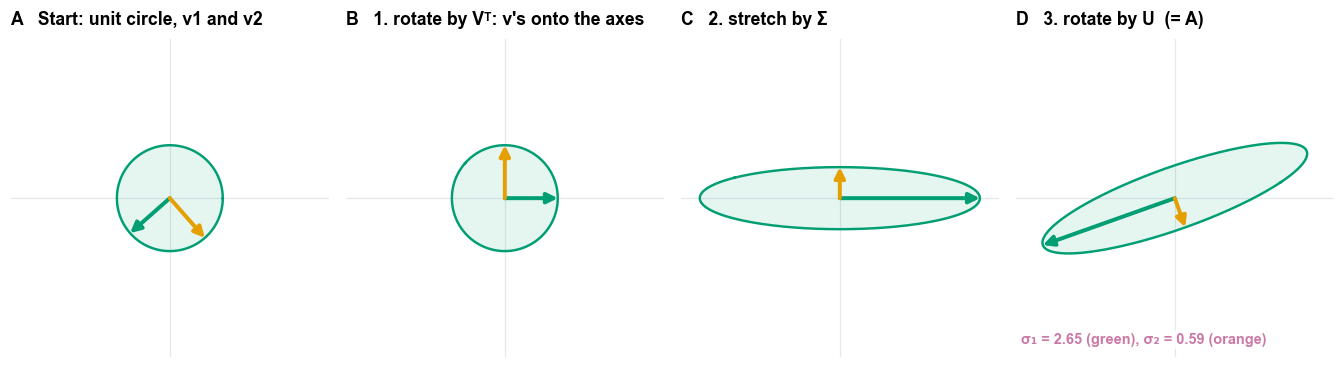

In [3]:
U2, s2, Vt2 = draw_svd_circle()

**그림에서 볼 것**
- A: 원 위의 초록 v₁ 과 주황 v₂ 는 서로 직각입니다.
- B: $V^\top$ 가 두 방향을 가로·세로 축으로 돌려 놓습니다. 원은 여전히 원입니다.
- C: Σ 가 가로는 σ₁ 배, 세로는 σ₂ 배 늘여 타원을 만듭니다.
- D: U 가 돌려서 최종 타원이 됩니다. 이것이 A 를 원에 적용한 결과이고, 초록·주황 화살표가 σ₁u₁, σ₂u₂ 입니다.

**수식 풀어 읽기**

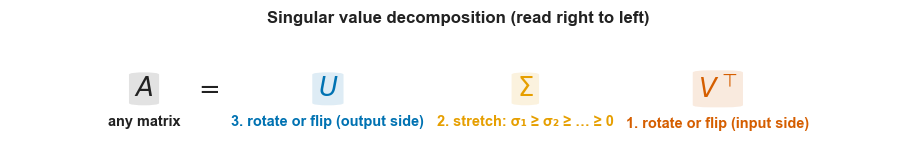

In [4]:
show_formula([(r"$A$", COL["ink"], "any matrix"), (r"$=$", None, None),
              (r"$U$", COL["e1"], "3. rotate or flip (output side)"), (r"$\Sigma$", COL["extra"], "2. stretch: σ₁ ≥ σ₂ ≥ … ≥ 0"),
              (r"$V^\top$", COL["e2"], "1. rotate or flip (input side)")],
             title="Singular value decomposition (read right to left)")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $V$ 의 열 $v_i$ | "오른쪽 특이벡터" | 입력 쪽 특별한 직각 방향 | A 의 초록·주황 |
| $\sigma_i$ | "시그마 i, 특잇값" | 그 방향의 늘어나는 배율 | C 의 가로·세로 반지름 |
| $U$ 의 열 $u_i$ | "왼쪽 특이벡터" | 출력 쪽 타원의 축 방향 | D 의 화살표 방향 |

확인: $U\Sigma V^\top = A$, $Av_i = \sigma_i u_i$, U 와 V 의 열은 각각 서로 직각인 단위 벡터.

In [5]:
A2 = np.array([[2.0, 1.5], [0.3, 1.0]])
assert np.allclose(U2 @ np.diag(s2) @ Vt2, A2)
for i in range(2):
    assert np.allclose(A2 @ Vt2[i], s2[i] * U2[:, i])
assert np.allclose(U2.T @ U2, np.eye(2)) and np.allclose(Vt2 @ Vt2.T, np.eye(2))
print("특잇값:", np.round(s2, 3), "  U Σ Vᵀ == A")

특잇값: [2.645 0.586]   U Σ Vᵀ == A


이 그림은 U 를 순수한 회전($\det U = +1$)으로 맞추도록 특이벡터의 부호를 골랐습니다. det A < 0 인 행렬(예: [[1, 2], [2, 1]], det = −3)이면 넓이 부호가 뒤집혀야 하므로, 그 뒤집기는 $V^\top$ 쪽에 들어갑니다($\det V^\top = -1$). 아래 셀의 주석을 풀어 직접 보세요.

**직접 바꿔 보기**: `draw_svd_circle(A=((1, 2), (2, 1)))`

In [6]:
# draw_svd_circle(A=((1, 2), (2, 1)))
Uf, sf, Vtf = np.linalg.svd(np.array([[1.0, 2.0], [2.0, 1.0]]))
if np.linalg.det(Uf) < 0:
    Uf[:, 1] *= -1; Vtf[1] *= -1
assert np.isclose(np.linalg.det(Uf), 1) and np.isclose(np.linalg.det(Vtf), -1)
print("det A = −3 일 때: det U =", round(np.linalg.det(Uf), 6), ", det Vᵀ =", round(np.linalg.det(Vtf), 6), "(뒤집기)")

det A = −3 일 때: det U = 1.0 , det Vᵀ = -1.0 (뒤집기)


## 2. SVD = rank-1 조각들의 합

**한 줄 정의**: $A = \sum_i \sigma_i\, u_i v_i^\top$. 조각 하나 $\sigma_i u_i v_i^\top$ 는 M2 의 네 번째 눈에서 본 rank-1 표이고, σ 가 그 조각의 크기입니다.

**왜 필요한가**: σ 가 큰 순서로 조각을 쌓으면, 앞의 몇 조각이 행렬의 큰 줄기를 거의 다 담습니다. 이것이 압축, 잡음 제거, PCA 의 바탕입니다.

**숫자로 따라가기**: 아래는 60 × 90 장난감 그림(행렬)입니다. 조각 하나는 60 + 90 + 1 = 151 개 숫자로 적히는데, 원래 그림은 5,400 개 숫자입니다.

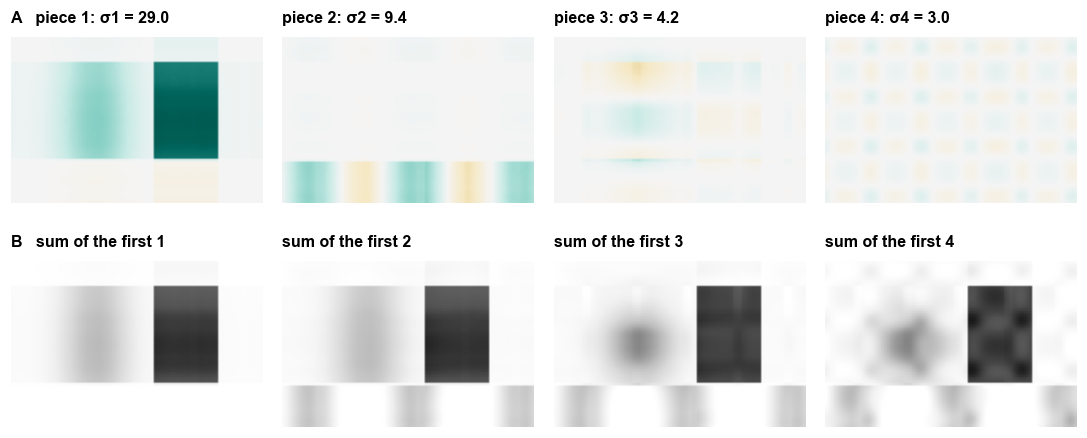

In [7]:
img = toy_image()
Ui, si, Vti = draw_rank1_pieces(img)

**그림에서 볼 것**
- A(윗줄): 조각 하나하나입니다. 각 조각은 "세로 패턴 × 가로 패턴" 하나라 줄무늬·격자 모양이고, 초록은 +, 갈색은 − 입니다. 조각이 뒤로 갈수록 σ 가 작아 색이 옅습니다.
- B(아랫줄): 조각을 차례로 더한 결과입니다. 조각 네 개만으로 그림의 큰 덩어리(왼쪽 둥근 얼룩, 오른쪽 진한 사각형)가 보이기 시작합니다.

**수식 풀어 읽기**

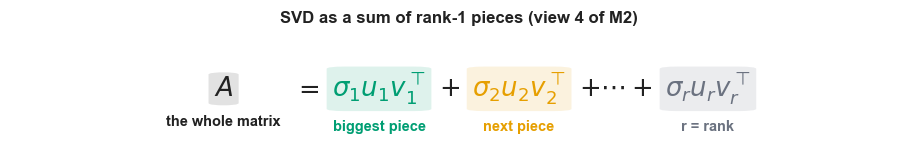

In [8]:
show_formula([(r"$A$", COL["ink"], "the whole matrix"), (r"$=$", None, None),
              (r"$\sigma_1 u_1 v_1^\top$", COL["result"], "biggest piece"), (r"$+$", None, None),
              (r"$\sigma_2 u_2 v_2^\top$", COL["extra"], "next piece"), (r"$+\cdots+$", None, None),
              (r"$\sigma_r u_r v_r^\top$", COL["muted"], "r = rank")],
             title="SVD as a sum of rank-1 pieces (view 4 of M2)")

In [9]:
recon = sum(si[k] * np.outer(Ui[:, k], Vti[k]) for k in range(len(si)))
assert np.allclose(recon, img)
assert np.linalg.matrix_rank(si[0] * np.outer(Ui[:, 0], Vti[0])) == 1
print("조각을 모두 더하면 원래 행렬, 조각 하나의 rank = 1. 조각 수(= rank):", np.linalg.matrix_rank(img))

조각을 모두 더하면 원래 행렬, 조각 하나의 rank = 1. 조각 수(= rank): 19


## 3. 저차원 근사: 큰 조각 k 개만 남기면 가장 가깝다

**한 줄 정의**: 처음 k 개 조각만 남긴 $A_k$ 는 **rank 가 k 이하인** 모든 행렬 중 A 에 가장 가까운 행렬입니다(Eckart–Young [3][10][11]). "가깝다"를 어떤 길이로 재느냐에 따라 오차의 값이 다릅니다.
- Frobenius 노름(모든 칸 차이의 제곱합의 제곱근): 오차 = $\sqrt{\sigma_{k+1}^2 + \sigma_{k+2}^2 + \cdots}$ [10][11]
- 스펙트럴 노름(가장 많이 늘어나는 방향의 배율): 오차 = $\sigma_{k+1}$ [11]

**왜 필요한가**: "작게 줄이되 가장 덜 잃는 방법"이 정해져 있다는 뜻입니다. 숫자 수는 $k(m + n + 1)$ 로 줄어듭니다.

**숫자로 따라가기**: 60 × 90 그림을 rank 8 로 줄이면 숫자가 8 × 151 = 1,208 개로 원래의 약 22% 입니다.

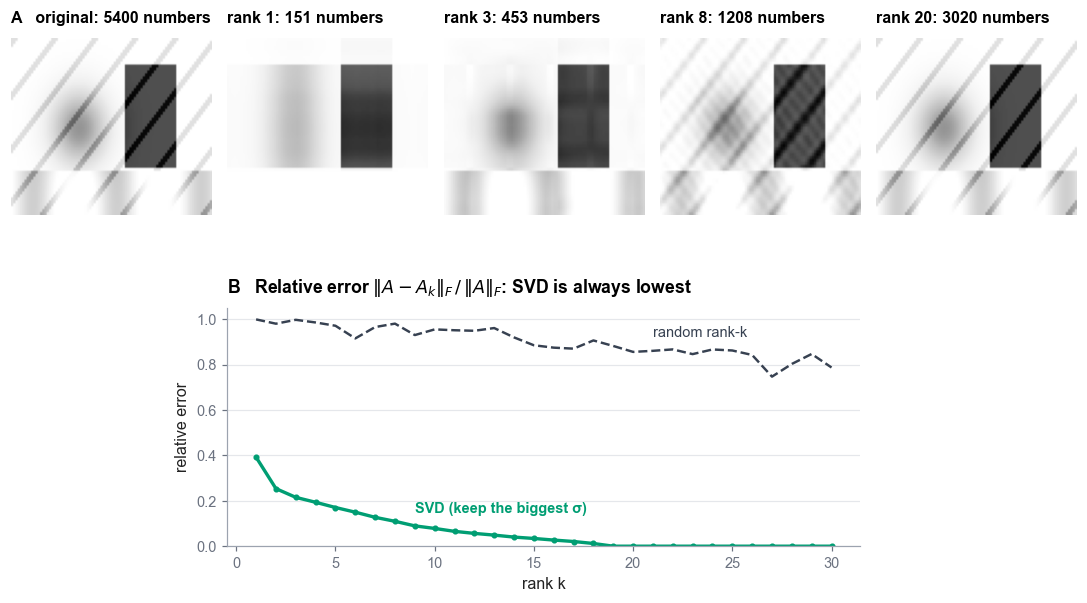

In [10]:
s_img, err_svd, err_rand = draw_low_rank(img)

**그림에서 볼 것**
- A: rank 1 은 흐릿한 덩어리뿐이지만 rank 8 이면 대부분의 모양이 보입니다. 이 장난감 그림의 rank 는 19 라서, rank 20 근사는 원본과 **정확히** 같습니다(오차 0). 제목의 숫자가 저장에 필요한 숫자 수입니다.
- B: 같은 rank 로 줄였을 때의 상대 오차입니다. 초록(SVD)은 회색 점선(무작위 방향으로 줄이기)보다 늘 아래에 있습니다. 이것이 Eckart–Young 이 말하는 "가장 좋은 rank-k" 입니다.

**수식 풀어 읽기**

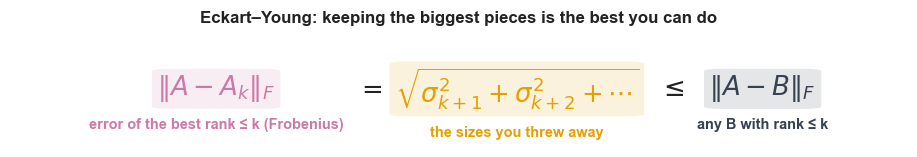

In [11]:
show_formula([(r"$\| A - A_k \|_F$", COL["highlight"], "error of the best rank ≤ k (Frobenius)"), (r"$=$", None, None),
              (r"$\sqrt{\sigma_{k+1}^2 + \sigma_{k+2}^2 + \cdots}$", COL["extra"], "the sizes you threw away"),
              (r"$\;\leq\;$", None, None), (r"$\| A - B \|_F$", COL["grid1"], "any B with rank ≤ k")],
             title="Eckart–Young: keeping the biggest pieces is the best you can do")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $A_k$ | "A 케이" | 처음 k 조각의 합 | A 의 그림들 |
| $\lVert\cdot\rVert_F$ | "프로베니우스 노름" | 모든 칸 차이를 제곱해 더한 뒤 제곱근(행렬의 길이) | B 의 세로축 |
| $\lVert\cdot\rVert_2$ | "스펙트럴 노름" | 단위 벡터를 가장 많이 늘리는 배율(= 가장 큰 특잇값) | - |

오차 식과 "무작위보다 늘 낫다"를 확인합니다.

In [12]:
for k in (1, 3, 8, 20):
    Ak = (Ui[:, :k] * si[:k]) @ Vti[:k]
    assert np.isclose(np.linalg.norm(img - Ak), np.sqrt(np.sum(si[k:] ** 2)))          # Frobenius
    if k < np.linalg.matrix_rank(img):
        assert np.isclose(np.linalg.norm(img - Ak, 2), si[k])                        # 스펙트럴 = σ_{k+1}
rk = np.linalg.matrix_rank(img)
A20 = (Ui[:, :20] * si[:20]) @ Vti[:20]
assert rk == 19 and np.allclose(A20, img)
print("이 그림의 rank =", rk, "→ rank 20 근사는 원본과 같음 (최대 칸 차이", f"{np.abs(A20 - img).max():.1e})")
assert all(e_s <= e_r + 1e-9 for e_s, e_r in zip(err_svd, err_rand))
print("rank 8 저장 비율:", round(8 * (60 + 90 + 1) / (60 * 90), 3), "  SVD 오차가 30 개 rank 모두에서 무작위보다 작거나 같음")

이 그림의 rank = 19 → rank 20 근사는 원본과 같음 (최대 칸 차이 7.8e-15)
rank 8 저장 비율: 0.224   SVD 오차가 30 개 rank 모두에서 무작위보다 작거나 같음


## 4. SVD 와 PCA 는 같은 것

**한 줄 정의**: 유전자마다 평균을 뺀 데이터 $X_c$(표본 × 유전자)를 $U\Sigma V^\top$ 로 쪼개면, V 의 열이 PCA 방향(공분산의 고유벡터)이고 $\sigma_i^2/(n-1)$ 이 고윳값입니다 [4].

**왜 필요한가**: 실제 PCA 프로그램도 SVD 를 씁니다. R 의 `prcomp` 는 "공분산 행렬의 고유분해가 아니라, 평균을 뺀(필요하면 크기도 맞춘) 데이터 행렬의 SVD 로" 계산하고 이것이 수치 정확도 면에서 보통 낫다고 적습니다 [12]. scikit-learn 의 PCA 도 SVD 로 차원을 줄이지만, 기본 설정('auto')에서는 특징이 1000 개보다 적고 표본이 그 10 배보다 많으면 공분산 고유분해(covariance_eigh)로 바꿉니다 [13]. 식으로는 $X_c^\top X_c = V\Sigma^2 V^\top$ 이라 M4 의 $Q\Lambda Q^\top$ 와 모양이 같습니다.

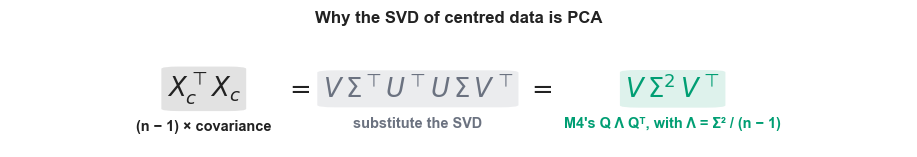

In [13]:
show_formula([(r"$X_c^\top X_c$", COL["ink"], "(n − 1) × covariance"), (r"$=$", None, None),
              (r"$V\,\Sigma^\top U^\top U\,\Sigma\,V^\top$", COL["muted"], "substitute the SVD"), (r"$=$", None, None),
              (r"$V\,\Sigma^2\,V^\top$", COL["result"], "M4's Q Λ Qᵀ, with Λ = Σ² / (n − 1)")],
             title="Why the SVD of centred data is PCA")

In [14]:
rng = np.random.default_rng(4)
Xd = rng.normal(size=(80, 5)) @ rng.normal(size=(5, 5)); Xdc = Xd - Xd.mean(0)
_, sd, Vtd = np.linalg.svd(Xdc, full_matrices=False)
lam_d, Q_d = np.linalg.eigh(np.cov(Xdc.T)); order = np.argsort(lam_d)[::-1]; lam_d, Q_d = lam_d[order], Q_d[:, order]
assert np.allclose(sd ** 2 / (80 - 1), lam_d)
assert np.allclose(np.abs(Vtd.T), np.abs(Q_d), atol=1e-6)          # 부호만 다를 수 있음
print("σ²/(n−1) == 공분산 고윳값:", np.round(sd ** 2 / 79, 3))

σ²/(n−1) == 공분산 고윳값: [14.068  6.362  3.693  0.825  0.126]


## 5. NMF: 음수 없이 쪼개기

**한 줄 정의**: NMF(non-negative matrix factorization)는 음수가 없는 행렬 V 를 음수가 없는 두 행렬의 곱 $V \approx WH$ 로 근사합니다 [5][6].

**왜 필요한가**: SVD 조각은 + 와 − 가 섞여 있어 "더하고 빼서" 데이터를 만듭니다. 변이 개수처럼 음수가 없는 데이터에서는 "재료를 **더하기만** 해서 만든다"가 자연스럽고, Lee 와 Seung 은 이 음수 없음 조건이 더하기만 허용해 **부분(parts)** 을 배우게 한다고 설명합니다 [5].

**숫자로 따라가기**: 장난감 signature 3 개(COSMIC 아님)로 표본 40 개의 catalogue(96 × 40)를 만들고, SVD 와 NMF 로 각각 세 조각을 뽑아 비교합니다.

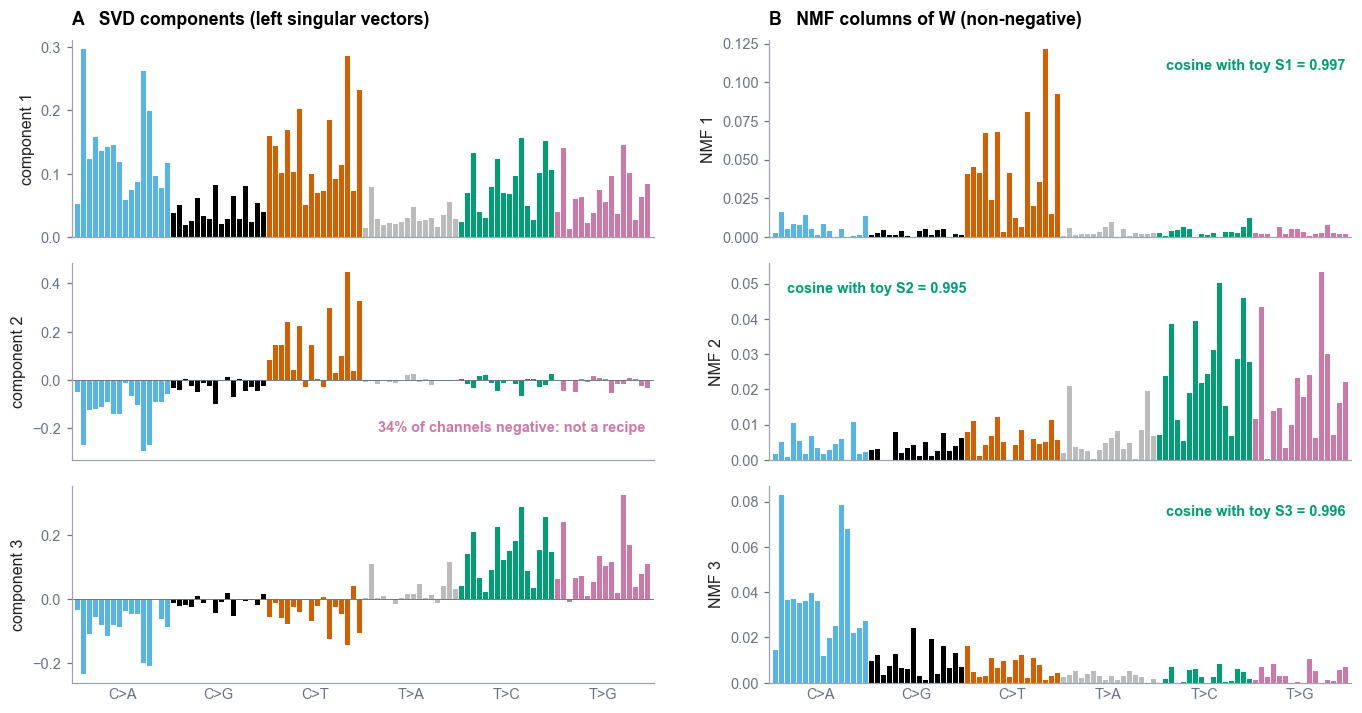

In [15]:
P = toy_signatures(); V, E = make_catalogues(P)
Wn, Hn, hist, cs = draw_svd_vs_nmf(V, P)

**그림에서 볼 것**
- 막대 색은 96칸 그림의 관례적인 치환 6 종류 구분입니다(이 그림에서만 쓰는 색).
- A: SVD 의 두 번째·세 번째 성분은 0 선 아래로 내려간 칸이 많습니다. "이 변이를 음수만큼 만든다"는 뜻이라 조리법으로 읽을 수 없습니다.
- B: NMF 의 W 열은 모두 0 이상이고, 진짜 장난감 signature 와의 코사인 유사도(초록 숫자)가 1 에 가깝습니다.

In [16]:
assert (Wn >= 0).all() and (Hn >= 0).all() and min(cs) > 0.95
print("NMF signature 와 진짜의 코사인:", np.round(cs, 3))

NMF signature 와 진짜의 코사인: [0.997 0.995 0.996]


## 6. 곱셈 갱신 직접 짜기

**한 줄 정의**: Lee 와 Seung 의 곱셈 갱신은 W, H 의 각 칸에 "지금 얼마나 모자라거나 넘치는지"를 뜻하는 비율을 곱해 갑니다. 이렇게 하면 $\lVert V - WH\rVert$ 가 **절대 늘지 않고**, 0 이상이던 칸은 계속 0 이상입니다 [6].

**왜 필요한가**: 비율을 곱하기만 하니 음수가 생길 수 없습니다. 다만 수렴에 대해서는 조심해야 합니다. Lee 와 Seung 은 이 반복이 국소 최적으로 수렴한다고 적었지만 [6], 그들이 정리 1 에서 증명한 것은 "오차가 늘지 않는다"는 것입니다. Lin(2007)은 이 곱셈 갱신이 정지점으로 수렴한다는 증명은 없다고 지적하고, 조금 고친 갱신을 제안했습니다 [9]. 즉 **오차는 늘지 않지만, 정지점(더 나은 쪽으로 움직일 수 없는 점)으로 간다는 보장은 없고**, 시작점마다 끝나는 곳이 다를 수 있습니다. 그래서 여러 번 돌려 같은 답이 나오는지 봐야 합니다(7절).

**용어 사전**
- 정지점: 그 자리에서 조금 움직여도 오차가 (1 차적으로) 줄지 않는 점. 국소 최소가 되기 위한 필요조건입니다 [9].
- 국소 최적: 그 근처에서는 가장 좋은 답이지만, 전체에서 가장 좋은 답(전역 최적)은 아닐 수 있는 답.

**수식 풀어 읽기**

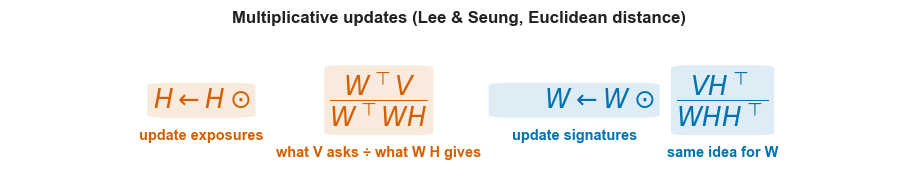

In [17]:
show_formula([(r"$H \leftarrow H \odot$", COL["e2"], "update exposures"),
              (r"$\dfrac{W^\top V}{W^\top W H}$", COL["e2"], "what V asks ÷ what W H gives"),
              (r"$\qquad W \leftarrow W \odot$", COL["e1"], "update signatures"),
              (r"$\dfrac{V H^\top}{W H H^\top}$", COL["e1"], "same idea for W")],
             title="Multiplicative updates (Lee & Seung, Euclidean distance)", height=1.6)

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\odot$ | "칸마다 곱하기" | 같은 자리끼리 곱함(행렬 곱이 아님) | - |
| 분수 | "칸마다 나누기" | 1 보다 크면 그 칸을 키우고, 작으면 줄임 | - |
| $\leftarrow$ | "바꿔 넣는다" | 계산한 값으로 갱신 | 아래 그림의 걸음 하나 |

**기호 사전**: $\odot$ = "같은 자리 칸끼리 곱하기(Hadamard 곱)". 위 `nmf()` 함수의 두 줄 `H *= (W.T @ V) / (W.T @ W @ H)`, `W *= (V @ H.T) / (W @ H @ H.T)` 가 이 식 그대로입니다. V = WH 이면 비율이 1 이라 더 바뀌지 않습니다 [6].

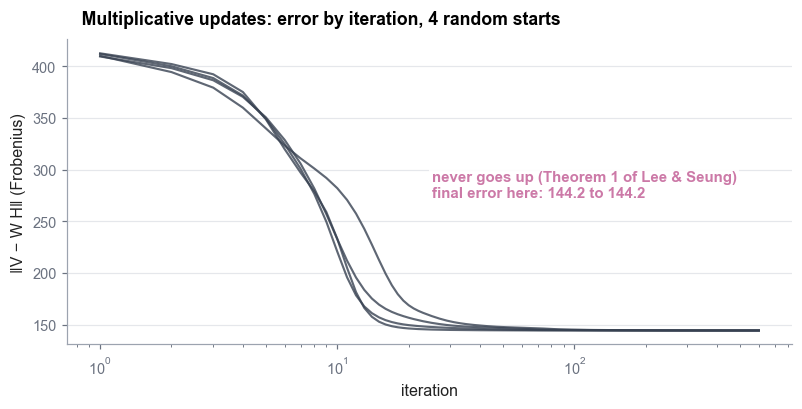

In [18]:
finals = draw_convergence(V)

**그림에서 볼 것**
- 회색 선 네 개가 무작위 시작점 네 개입니다. 모든 선이 오르막 없이 내려갑니다(정리 1).
- 이 장난감에서는 네 선이 거의 같은 높이에서 끝납니다(자주색 글씨의 범위). 데이터가 단순하고 k 가 진짜 개수(3)와 같아서입니다. 데이터가 복잡하거나 k 가 크면 시작점마다 다른 곳에 멈출 수 있어, 7절처럼 여러 번 돌려 봅니다.

In [19]:
assert np.all(np.diff(hist) <= 1e-6 * hist[0])
print("오차가 한 번도 늘지 않음. 처음", round(hist[0], 1), "→ 마지막", round(hist[-1], 1))
print("시작점 4 개의 마지막 오차:", np.round(finals, 2))

오차가 한 번도 늘지 않음. 처음 411.9 → 마지막 144.2
시작점 4 개의 마지막 오차: [144.23 144.19 144.18 144.24]


## 7. signature 개수 k 고르기

**한 줄 정의**: 최적해 기준으로는(각 k 에서 가장 좋은 분해를 찾는다면) k 를 늘릴수록 재구성 오차는 줄거나 같기 때문에, 오차만 보면 k 를 정할 수 없습니다. (실제 곱셈 갱신은 6절대로 최적해를 보장하지 않아, 한 번의 실행에서는 드물게 거꾸로 될 수도 있습니다.) Alexandrov 등은 여러 번 돌려 **signature 가 재현되고 오차가 낮은** k 를 고릅니다 [7].

**왜 필요한가**: k 가 너무 크면 잡음까지 signature 로 쪼개고, 그런 signature 는 시작점마다 다르게 나와 믿을 수 없습니다.

**숫자로 따라가기**: 진짜 signature 가 3 개인 장난감 데이터에서 k = 1~6 을 시작점 5 개씩 돌려, 오차와 "실행끼리 signature 가 얼마나 같은가(코사인)"를 잽니다.

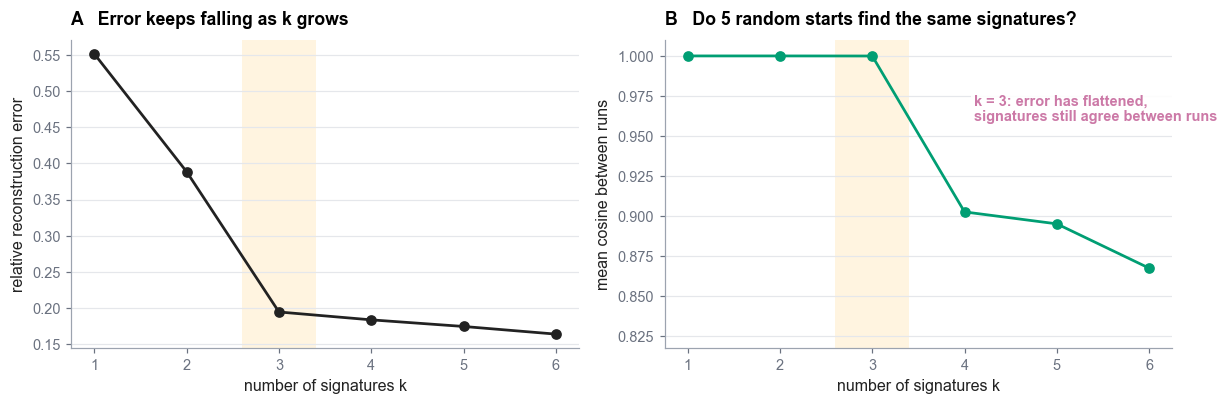

In [20]:
errs, stab = draw_choose_k(V)

**그림에서 볼 것**
- A: 오차는 k = 3 까지 크게 줄고, 그 뒤에는 거의 평평하지만 조금씩은 계속 줄어듭니다. 그래서 오차만으로는 "어디서 멈출지"가 애매합니다.
- B: k = 3 까지는 다섯 번 돌린 결과가 서로 같은 signature 를 냅니다(코사인 ≈ 1). k 가 그보다 커지면 실행마다 다르게 쪼개 코사인이 내려갑니다.
- 옅은 띠(k = 3)가 "오차는 충분히 낮고, 재현되는" 자리입니다. 이 결과는 이 노트북의 장난감 시뮬레이션입니다.

In [21]:
assert all(e1 >= e2 - 1e-9 for e1, e2 in zip(errs, errs[1:]))         # 이 실행에서는 k 가 늘면 오차가 줄거나 같음
assert stab[2] > 0.98 and stab[2] > stab[-1]
print("상대 오차:", np.round(errs, 3)); print("실행 간 코사인:", np.round(stab, 3))

상대 오차: [0.551 0.388 0.195 0.184 0.175 0.164]
실행 간 코사인: [1.    1.    1.    0.902 0.895 0.867]


> **시퀀싱 데이터에서는** mutational catalogue 행렬 M(96 × 표본 수)을 signature 행렬 P(96 × N)와 노출량 E(N × 표본 수)의 곱으로 쪼개는 것이 signature 추출입니다(M ≈ P × E) [7]. Alexandrov 등의 방법은 곱셈 갱신 NMF 를 부트스트랩한 데이터에 여러 번 적용하고, 재현성(평균 silhouette width)과 평균 Frobenius 재구성 오차로 N 을 고릅니다 [7]. (부트스트랩 = 데이터를 무작위로 다시 뽑아 같은 분석을 여러 번 해서, 결과가 얼마나 흔들리는지 보는 방법.) 이 노트북의 `nmf()` 는 그 생각만 줄여 옮긴 것이고, 실제 도구(SigProfilerExtractor 등)의 세부 절차와는 다릅니다.

## 8. 응용: LoRA 는 낮은 rank 의 갱신

**한 줄 정의**: LoRA 는 미리 학습된 가중치 $W_0$ 는 고정하고, 갱신 $\Delta W$ 를 두 작은 행렬의 곱 $BA$ 로 제한해 그것만 학습합니다. $B$ 는 d × r, $A$ 는 r × k, $r \ll \min(d, k)$ 입니다 [8].

**왜 필요한가**: d × k 갱신 전체 대신 r(d + k) 개 숫자만 배우면 됩니다. Hu 등은 GPT-3 175B 에서 학습할 숫자를 1만 배 줄였다고 보고합니다 [8]. BA 의 rank 는 r 이하이므로, M2 의 눈으로 보면 "rank-1 조각 r 개의 합"만 배우는 셈입니다.

**숫자로 따라가기**: d = k = 4096, r = 8 이면 전체 갱신은 1,677만 개, LoRA 는 8 × (4096 + 4096) = 65,536 개로 256 배 적습니다.

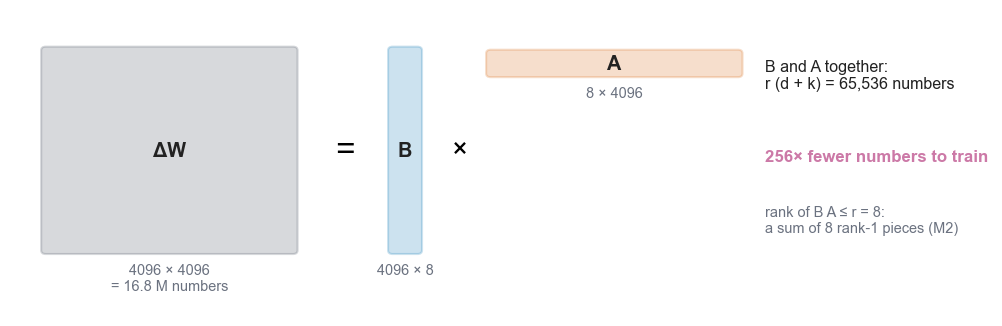

In [22]:
draw_lora()

**그림에서 볼 것**
- 큰 회색 정사각형(ΔW, 4096 × 4096)을 얇은 파란 B(4096 × 8)와 납작한 빨간 A(8 × 4096)의 곱으로 대신합니다.
- 학습할 숫자가 256 배 적습니다(자주색 글씨).

In [23]:
d_, k_, r_ = 4096, 4096, 8
assert d_ * k_ == 16_777_216 and r_ * (d_ + k_) == 65_536 and d_ * k_ // (r_ * (d_ + k_)) == 256
Bm = rng.normal(size=(64, 4)); Am = rng.normal(size=(4, 48))
assert np.linalg.matrix_rank(Bm @ Am) == 4
print("ΔW 전체 / LoRA =", d_ * k_ // (r_ * (d_ + k_)), "배,  rank(BA) =", np.linalg.matrix_rank(Bm @ Am), "≤ r")

ΔW 전체 / LoRA = 256 배,  rank(BA) = 4 ≤ r


## 연습 문제

1. 특잇값이 10, 5, 1, 0.5 인 행렬을 rank 2 로 줄일 때의 Frobenius 오차는?
2. 100 × 200 행렬을 rank 5 로 저장하면 숫자가 몇 개 필요한가요? 원래는?
3. SVD 의 성분 대신 NMF 를 signature 추출에 쓰는 이유는?
4. NMF 의 k 를 오차만 보고 고르면 안 되는 이유는?

<details><summary>정답 보기</summary>

1. $\sqrt{1^2 + 0.5^2} = \sqrt{1.25} \approx 1.118$.
2. 5 × (100 + 200 + 1) = 1,505 개. 원래는 20,000 개.
3. catalogue 와 노출량은 음수가 없는 양이라, 더하기만으로 만드는 NMF 조각이 "재료(signature)"로 읽힙니다. SVD 성분은 음수 칸이 있어 그렇게 읽을 수 없습니다.
4. 최적해 기준으로는 k 를 늘리면 오차가 줄거나 같아서, 오차만으로는 멈출 자리가 없기 때문입니다. 여러 번 돌려도 같은 signature 가 나오는지(재현성)를 함께 봐야 합니다.

</details>

In [24]:
assert np.isclose(np.sqrt(1 ** 2 + 0.5 ** 2), 1.118, atol=1e-3)
assert 5 * (100 + 200 + 1) == 1505 and 100 * 200 == 20000

## 정리

- SVD 는 모든 행렬을 회전·늘이기·회전 $U\Sigma V^\top$ 로, 또는 rank-1 조각의 합 $\sum \sigma_i u_i v_i^\top$ 로 쪼갭니다.
- 큰 조각 k 개만 남기는 것이 rank ≤ k 중 가장 좋은 근사이고(Eckart–Young), 오차는 버린 σ 들로 정해집니다(Frobenius 는 제곱합의 제곱근, 스펙트럴은 σ_{k+1}).
- 평균을 뺀 데이터의 SVD 가 곧 PCA 입니다($\sigma^2/(n-1)$ = 고윳값).
- 음수가 없는 데이터는 NMF 로 "재료 × 양"으로 쪼갭니다. 곱셈 갱신은 오차를 늘리지 않지만 정지점·최적해로 간다는 보장은 없어, 여러 번 돌려 재현성을 보고 k 를 고릅니다. signature 추출이 바로 이것입니다.
- LoRA 는 갱신을 rank r 로 묶어 학습할 숫자를 크게 줄입니다.

## 출처

1. MIT OpenCourseWare, 18.06 Linear Algebra (Gilbert Strang), Spring 2010, Video Lectures 목록. https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/video_galleries/video-lectures/ — 머리의 "같이 볼 강의" 회차와 제목만 확인했습니다(Lecture 29·31·33). 본문의 그림·식·숫자는 이 노트북에서 직접 계산한 것이고, 이 출처에 기대지 않습니다.
2. 3Blue1Brown (Grant Sanderson), "Essence of linear algebra" 재생목록. https://www.youtube.com/playlist?list=PLZHQObOWTQDPD3MizzM2xVFitgF8hE_ab — 16 개 장의 제목을 확인했고, SVD 를 제목으로 한 장은 없습니다.
3. Eckart C, Young G (1936). The approximation of one matrix by another of lower rank. *Psychometrika* 1:211–218. doi:10.1007/BF02288367 — 본문 PDF 를 기관 네트워크로 열어 확인했습니다. 근사의 기준은 모든 칸 차이의 제곱합(Frobenius)이며, 원문은 이를 "requiring a least-squares solution of the approximation problem, every element of the given matrix being given equal weight" 라고 적습니다(3절의 Frobenius 문장). 스펙트럴 노름 쪽 식은 [10][11] 과 이 노트북의 숫자 확인을 근거로 했습니다.
4. Jolliffe IT, Cadima J (2016). Principal component analysis: a review and recent developments. *Phil. Trans. R. Soc. A* 374:20150202. doi:10.1098/rsta.2015.0202, PMC4792409. — "it can be obtained as the solution to an eigenproblem or, alternatively, from the singular value decomposition (SVD) of the (centred) data matrix" (4절).
5. Lee DD, Seung HS (1999). Learning the parts of objects by non-negative matrix factorization. *Nature* 401:788–791. doi:10.1038/44565, PMID 10548103. — 초록 "These constraints lead to a parts-based representation because they allow only additive, not subtractive, combinations" (5절).
6. Lee DD, Seung HS (2001). Algorithms for non-negative matrix factorization. *Advances in Neural Information Processing Systems 13* (NIPS 2000). https://papers.nips.cc/paper_files/paper/2000/hash/f9d1152547c0bde01830b7e8bd60024c-Abstract.html — Theorem 1 의 곱셈 갱신과 "The Euclidean distance ‖V − WH‖ is nonincreasing under the update rules", "perfect reconstruction is necessarily a fixed point", "guaranteed to converge to a locally optimal matrix factorization"(저자들의 주장, 6절에서 [9] 와 함께 읽음).
7. Alexandrov LB, Nik-Zainal S, Wedge DC, Campbell PJ, Stratton MR (2013). Deciphering signatures of mutational processes operative in human cancer. *Cell Reports* 3(1):246–259. doi:10.1016/j.celrep.2012.12.008, PMID 23318258. — "M ≈ P × E" (Equation 3), "we use NMF to solve our BSS cancer genomics problem", "Apply the multiplicative update algorithm (Lee and Seung, 1999) … to the bootstrapped data", "We select the value of N for which the extracted processes are reproducible and the reconstruction error is low", Figure 2 설명 "signature reproducibility, measured using average silhouette width" (7절).
8. Hu EJ, et al. (2021). LoRA: Low-Rank Adaptation of Large Language Models. arXiv:2106.09685. https://arxiv.org/abs/2106.09685 — "W0 + ∆W = W0 + BA, where B ∈ R^{d×r}, A ∈ R^{r×k}, and the rank r ≪ min(d, k)", 초록 "reduce the number of trainable parameters by 10,000 times" (8절).
9. Lin C-J (2007). On the convergence of multiplicative update algorithms for nonnegative matrix factorization. *IEEE Transactions on Neural Networks* 18(6):1589–1596. doi:10.1109/TNN.2007.895831 — 초록(OpenAlex 에서 열람) "for the common NMF approach of minimizing the Euclidean distance … no proof has shown that multiplicative updates converge to a stationary point of the NMF optimization problem. Stationarity is important as it is a necessary condition of a local minimum" (6절).
10. MIT OpenCourseWare, 18.065 Matrix Methods in Data Analysis, Signal Processing, and Machine Learning (Gilbert Strang), Spring 2018, Lecture 7 "Eckart-Young: The Closest Rank k Matrix to A" 강의 쪽 Summary. https://ocw.mit.edu/courses/18-065-matrix-methods-in-data-analysis-signal-processing-and-machine-learning-spring-2018/resources/lecture-7-eckart-young-the-closest-rank-k-matrix-to-a/ — "A_k = σ1u1v1ᵀ + ⋯ + σkukvkᵀ (larger σ's from A = UΣVᵀ). The norm of A − A_k is below the norm of all other A − B_k. Frobenius norm squared = sum of squares of all entries" (3절).
11. Wikipedia, "Low-rank approximation" (2026-11-25 열람). https://en.wikipedia.org/wiki/Low-rank_approximation — Frobenius 노름에서 $\lVert D - \hat D^*\rVert_F = \min_{\mathrm{rank}(\hat D) \le k} \lVert D - \hat D\rVert_F = \sqrt{\sigma_{k+1}^2 + \cdots + \sigma_r^2}$, 스펙트럴 노름에서 $\lVert A - A_k\rVert_2 = \sigma_{k+1} \le \lVert A - B_k\rVert_2$ (3절). 두 식 모두 이 노트북에서 숫자로도 확인했습니다.
12. R 문서, `stats::prcomp` (R-devel). https://stat.ethz.ch/R-manual/R-devel/library/stats/html/prcomp.html — "The calculation is done by a singular value decomposition of the (centered and possibly scaled) data matrix, not by using eigen on the covariance matrix. This is generally the preferred method for numerical accuracy." (4절).
13. scikit-learn 문서, `sklearn.decomposition.PCA` (stable). https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html — "Linear dimensionality reduction using Singular Value Decomposition of the data … The input data is centered but not scaled", 'auto' 규칙 "if the input data has fewer than 1000 features and more than 10 times as many samples, then the 'covariance_eigh' solver is used" (4절).